# Recomendador de cultivos por zona agrícola

Este notebook genera una **preselección de cultivos por aptitud climática** para una zona definida con coordenadas o con un polígono GeoJSON.

- **NASA POWER** aporta series diarias georreferenciadas de temperatura media y precipitación.
- **FAO EcoCrop** aporta los rangos ambientales de temperatura, lluvia y duración del ciclo de cultivo.
- El algoritmo busca ventanas de cultivo posibles y ordena las especies por su puntuación climática media entre años.

El sistema no usa reseñas de películas ni los archivos `movies.txt.gz`. Tampoco es un modelo de ML entrenado: no hay en el proyecto etiquetas de cosecha/rendimiento para entrenar y validar un predictor supervisado. Es un recomendador climático explicable; todavía necesita suelo, agua de riego, variedad, calendario local y validación agronómica.


## 1. Dependencias y entorno

Selecciona el kernel **Python 3.13.17** en VS Code. Ejecuta la instalación con `%pip`, que instala en el entorno del kernel activo. Si el notebook solicita reiniciar el kernel, hazlo y continúa desde la celda de importaciones.

Se evitan dependencias geoespaciales pesadas: POWER recibe un punto representativo de la zona. Para una zona GeoJSON se usa el centro del rectángulo envolvente como punto de consulta; la escala regional de POWER no permite interpretar ese valor como medición parcelaria.


In [20]:
%pip install --upgrade pip
%pip install numpy pandas requests matplotlib openpyxl


Note: you may need to restart the kernel to use updated packages.
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- -----------

In [12]:
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

print("Python activo:", sys.version)
print("Ejecutable:", sys.executable)
if sys.version_info < (3, 13):
    print("AVISO: selecciona el kernel Python 3.13.17 antes de seguir.")

# La carpeta se resuelve tanto si Jupyter abre desde la raíz del proyecto
# como si abre directamente desde ml/.
CWD = Path.cwd()
ML_DIR = CWD if CWD.name.lower() == "ml" else CWD / "ml"
DATA_DIR = ML_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Ejemplo de punto de prueba del proyecto en la costa de Ica, Perú.
# Sustituir por las coordenadas reales de la zona antes de usar resultados.
ZONE_NAME = "Punto de prueba (editar por zona agrícola real)"
ZONE_LAT = -13.718
ZONE_LON = -76.148
GEOJSON_PATH = DATA_DIR / "zona_agricola.geojson"  # opcional

# Diez años completos para evitar que un año parcial sesgue el ranking.
START_DATE = "20150101"
END_DATE = "20241231"


Python activo: 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
Ejecutable: d:\Documentos_Guille\GitHub\NASA_SPACE_APPS_HACKATON\.venv\Scripts\python.exe


## 2. Ubicación de la zona

Se puede editar `ZONE_LAT` y `ZONE_LON` con el centro de la zona agrícola. De forma opcional, guarda un archivo `zona_agricola.geojson` dentro de `ml/data/`; la celda siguiente usa el centro del rectángulo envolvente de sus coordenadas. Para zonas grandes o con varios pisos ecológicos, conviene evaluar varios puntos por separado y no resumirlos en un solo centro.


In [13]:
def _collect_lon_lat(node, found):
    """Recorre las coordenadas de una geometría GeoJSON [lon, lat]."""
    if isinstance(node, (list, tuple)) and len(node) >= 2 and all(
        isinstance(v, (int, float)) for v in node[:2]
    ):
        lon, lat = float(node[0]), float(node[1])
        if -180 <= lon <= 180 and -90 <= lat <= 90:
            found.append((lon, lat))
        return
    if isinstance(node, (list, tuple)):
        for child in node:
            _collect_lon_lat(child, found)

if GEOJSON_PATH.exists():
    geojson = json.loads(GEOJSON_PATH.read_text(encoding="utf-8"))
    geometry = geojson.get("geometry") if geojson.get("type") == "Feature" else geojson
    if geojson.get("type") == "FeatureCollection":
        geometries = [f.get("geometry", {}) for f in geojson.get("features", [])]
        coords = []
        for geom in geometries:
            _collect_lon_lat(geom.get("coordinates", []), coords)
    else:
        coords = []
        _collect_lon_lat(geometry.get("coordinates", []), coords)
    if not coords:
        raise ValueError(f"No se encontraron coordenadas válidas en {GEOJSON_PATH}")
    lons, lats = zip(*coords)
    ZONE_LON = (min(lons) + max(lons)) / 2
    ZONE_LAT = (min(lats) + max(lats)) / 2
    ZONE_NAME = f"Zona GeoJSON: {GEOJSON_PATH.name}"

if not (-90 <= ZONE_LAT <= 90 and -180 <= ZONE_LON <= 180):
    raise ValueError("Revisa las coordenadas: latitud [-90, 90], longitud [-180, 180].")

print(f"Zona: {ZONE_NAME}")
print(f"Punto de consulta: latitud={ZONE_LAT:.5f}, longitud={ZONE_LON:.5f}")
print(f"Periodo NASA POWER: {START_DATE} a {END_DATE}")


Zona: Punto de prueba (editar por zona agrícola real)
Punto de consulta: latitud=-13.71800, longitud=-76.14800
Periodo NASA POWER: 20150101 a 20241231


## 3. Datos climáticos geoespaciales de NASA POWER

La consulta solicita `T2M` (temperatura media a 2 m, °C) y `PRECTOTCORR` (precipitación corregida, mm/día) para el punto de la zona. El notebook conserva las fechas y elimina valores faltantes de NASA (`-999`). POWER entrega datos de su celda de grilla más cercana; la resolución y la variabilidad dentro de la zona limitan el detalle que puede afirmarse.


In [14]:
POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

def request_power_year(year):
    """Consulta un año como máximo por llamada y devuelve T2M/lluvia con fecha."""
    start = max(START_DATE, f"{year}0101")
    end = min(END_DATE, f"{year}1231")
    if start > end:
        return pd.DataFrame()
    params = {
        "parameters": "T2M,PRECTOTCORR",
        "community": "AG",
        "longitude": ZONE_LON,
        "latitude": ZONE_LAT,
        "start": start,
        "end": end,
        "format": "JSON",
        "time-standard": "UTC",
    }
    response = requests.get(POWER_URL, params=params, timeout=120)
    response.raise_for_status()
    data = response.json()
    parameter_data = data.get("properties", {}).get("parameter", {})
    if not {"T2M", "PRECTOTCORR"}.issubset(parameter_data):
        raise ValueError(f"Respuesta POWER incompleta para {year}: {list(parameter_data)}")
    frame = pd.DataFrame(parameter_data)
    frame.index = pd.to_datetime(frame.index, format="%Y%m%d", errors="coerce")
    frame.index.name = "date"
    frame = frame.apply(pd.to_numeric, errors="coerce")
    fill = data.get("header", {}).get("fill_value", -999.0)
    frame = frame.replace(fill, np.nan).dropna(subset=["T2M", "PRECTOTCORR"])
    return frame, data

start_year = int(START_DATE[:4])
end_year = int(END_DATE[:4])
year_frames = []
power_metadata = None
for year in range(start_year, end_year + 1):
    result = request_power_year(year)
    downloaded_count = 0
    if isinstance(result, tuple):
        frame, metadata = result
        downloaded_count = len(frame)
        if not frame.empty:
            year_frames.append(frame)
            power_metadata = metadata
    print(f"{year}: {downloaded_count} filas válidas descargadas")
    time.sleep(0.25)  # evita enviar solicitudes consecutivas sin pausa

if not year_frames:
    raise ValueError("NASA POWER no devolvió días válidos para la zona y periodo elegidos.")
power_df = pd.concat(year_frames).sort_index()
power_df = power_df[~power_df.index.duplicated(keep="first")]

units = power_metadata.get("parameters", {}) if power_metadata else {}
print("Días válidos:", len(power_df))
print("Coordenadas reportadas por POWER:", power_metadata.get("geometry", {}).get("coordinates"))
print("Metadatos de variables:")
unit_table = pd.DataFrame(units).T
show_cols = [c for c in ["units", "longname"] if c in unit_table.columns]
display(unit_table[show_cols])
display(power_df.head())




2015: 365 filas válidas descargadas
2016: 366 filas válidas descargadas
2017: 365 filas válidas descargadas
2018: 365 filas válidas descargadas
2019: 365 filas válidas descargadas
2020: 366 filas válidas descargadas
2021: 365 filas válidas descargadas
2022: 365 filas válidas descargadas
2023: 365 filas válidas descargadas
2024: 366 filas válidas descargadas
Días válidos: 3653
Coordenadas reportadas por POWER: [-76.148, -13.718, 483.03]
Metadatos de variables:


,units,longname
T2M,C,Temperature at 2 Meters
PRECTOTCORR,mm/day,Precipitation Corrected


,T2M,PRECTOTCORR
date,,
2015-01-01,21.24,0.22
2015-01-02,19.95,0.56
2015-01-03,21.06,0.00
2015-01-04,21.40,0.00
2015-01-05,21.90,0.34


Temperatura media del periodo (°C): 19.86
Precipitación anual media (mm): 51.3


,temp_mean_c,rain_mm
mes,,
1,21.7,8.4
2,22.5,11.2
3,22.5,9.1
4,21.2,3.1
5,19.8,2.0
6,18.4,0.7
7,17.9,0.7
8,17.9,0.5
9,18.2,1.4


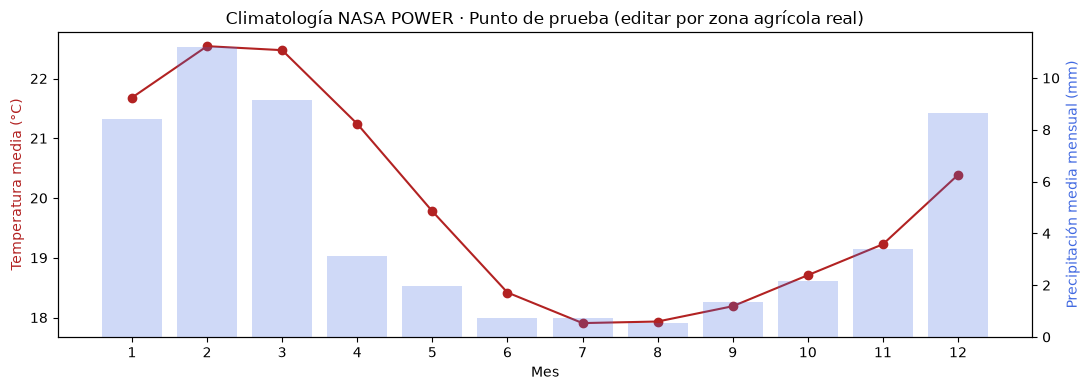

In [15]:
# Resumen climático mensual: temperatura media y precipitación mensual media.
monthly_by_year = power_df.groupby([power_df.index.year, power_df.index.month]).agg(
    temp_mean_c=("T2M", "mean"),
    rain_mm=("PRECTOTCORR", "sum"),
)
monthly_climatology = monthly_by_year.groupby(level=1).mean()
monthly_climatology.index.name = "mes"

annual_climatology = power_df.groupby(power_df.index.year).agg(
    temp_mean_c=("T2M", "mean"),
    rain_mm=("PRECTOTCORR", "sum"),
)
print("Temperatura media del periodo (°C):", round(power_df["T2M"].mean(), 2))
print("Precipitación anual media (mm):", round(annual_climatology["rain_mm"].mean(), 1))
display(monthly_climatology.round(1))

fig, ax1 = plt.subplots(figsize=(11, 4))
months = monthly_climatology.index.to_numpy()
ax1.plot(months, monthly_climatology["temp_mean_c"], marker="o", color="firebrick")
ax1.set_xlabel("Mes")
ax1.set_ylabel("Temperatura media (°C)", color="firebrick")
ax1.set_xticks(range(1, 13))
ax2 = ax1.twinx()
ax2.bar(months, monthly_climatology["rain_mm"], alpha=0.25, color="royalblue")
ax2.set_ylabel("Precipitación media mensual (mm)", color="royalblue")
plt.title(f"Climatología NASA POWER · {ZONE_NAME}")
plt.tight_layout()
plt.show()


## 4. Requisitos de cultivos: FAO EcoCrop

Se descarga el CSV público **EcoCrop_DB.csv** del proyecto OpenCLIM, que publica la base FAO EcoCrop y su metodología climática. Las columnas usadas son los límites y rangos óptimos de temperatura (`TMIN`, `TOPMN`, `TOPMX`, `TMAX`), precipitación por ciclo (`RMIN`, `ROPMN`, `ROPMX`, `RMAX`) y duración del ciclo (`GMIN`, `GMAX`). Perfiles incompletos se excluyen del ranking en vez de inventar los valores faltantes.


In [22]:
ECOCROP_URL = "https://raw.githubusercontent.com/OpenCLIM/ecocrop/main/EcoCrop_DB.csv"
ECOCROP_FILE = DATA_DIR / "EcoCrop_DB.csv"

if not ECOCROP_FILE.exists():
    eco_response = requests.get(ECOCROP_URL, timeout=90)
    eco_response.raise_for_status()
    ECOCROP_FILE.write_bytes(eco_response.content)

ecocrop = pd.read_csv(ECOCROP_FILE, low_memory=False, encoding="latin-1")
ecocrop.columns = [str(c).strip().upper() for c in ecocrop.columns]
required_columns = ["TMIN", "TOPMN", "TOPMX", "TMAX", "RMIN", "ROPMN", "ROPMX", "RMAX", "GMIN", "GMAX"]
missing_columns = [c for c in required_columns if c not in ecocrop.columns]
if missing_columns:
    raise ValueError(f"El CSV EcoCrop cambió de estructura; faltan columnas: {missing_columns}")

name_column = "COMNAME" if "COMNAME" in ecocrop.columns else ("AUTH" if "AUTH" in ecocrop.columns else None)
if name_column is None:
    raise ValueError("El CSV EcoCrop no contiene COMNAME ni AUTH para identificar las especies.")

print("Perfiles descargados:", len(ecocrop))
print("Columnas disponibles:", list(ecocrop.columns))
display(ecocrop[[name_column] + required_columns].head())


Perfiles descargados: 2568
Columnas disponibles: ['ECOPORTCODE', 'SCIENTIFICNAME', 'AUTH', 'FAMNAME', 'SYNO', 'COMNAME', 'LIFO', 'HABI', 'LISPA', 'PHYS', 'CAT', 'PLAT', 'TOPMN', 'TOPMX', 'TMIN', 'TMAX', 'ROPMN', 'ROPMX', 'RMIN', 'RMAX', 'PHOPMN', 'PHOPMX', 'PHMIN', 'PHMAX', 'LATOPMN', 'LATOPMX', 'LATMN', 'LATMX', 'ALTMX', 'LIOPMN', 'LIOPMX', 'LIMN', 'LIMX', 'DEP', 'DEPR', 'TEXT', 'TEXTR', 'FER', 'FERR', 'TOX', 'TOXR', 'SAL', 'SALR', 'DRA', 'DRAR', 'KTMPR', 'KTMP', 'PHOTO', 'CLIZ', 'ABITOL', 'ABISUS', 'INTRI', 'PROSY', 'GMIN', 'GMAX']


,COMNAME,TMIN,TOPMN,TOPMX,TMAX,RMIN,ROPMN,ROPMX,RMAX,GMIN,GMAX
0,"abelmoskus, america-neri, bakhua mun, bamia, b...",12.0,20.0,30.0,35.0,300.0,600.0,1200.0,2500.0,50.0,180.0
1,"neka (Simbo), bele (Fiji), pele (Tonga, Tuvalu...",16.0,22.0,30.0,36.0,1000.0,1200.0,2000.0,3000.0,365.0,365.0
2,"abelmosk, musk mallow, mushkdan, muskdana, kas...",10.0,20.0,30.0,35.0,900.0,1000.0,1400.0,1500.0,0.0,0.0
3,"Papuan wattle, auri, ear leaf acacia, tuhkehn ...",10.0,24.0,32.0,40.0,500.0,1200.0,2500.0,5000.0,180.0,240.0
4,"Ellington curse, klu, cassie, espino blanco, a...",7.0,20.0,32.0,42.0,150.0,400.0,1400.0,4000.0,60.0,240.0


## 5. Algoritmo de recomendación

Para cada especie con perfil completo, el algoritmo evalúa ventanas de cultivo de `GMIN`, punto medio entre `GMIN` y `GMAX`, y `GMAX` días. En cada ventana puntúa la temperatura media y la lluvia acumulada con una curva lineal entre límites absolutos y óptimos. La puntuación de la ventana es el menor de ambos componentes (el factor limitante); se toma la mejor ventana de cada año y luego se promedia entre años. Se prueban fechas de inicio cada siete días para mantener el cálculo manejable.

Es una simplificación climática inspirada en EcoCrop: no estima rendimiento, no evalúa heladas con temperatura mínima, suelo, riego disponible, plagas, mercado ni calendario agrícola local. El puntaje sirve para ordenar candidatos dentro de esta consulta, no es probabilidad de éxito.


In [23]:
def suitability_score(values, absolute_min, optimum_min, optimum_max, absolute_max):
    """Puntuación triangular/trapezoidal 0–100 entre límites EcoCrop."""
    x = np.asarray(values, dtype=float)
    lo, opt_lo, opt_hi, hi = map(float, (absolute_min, optimum_min, optimum_max, absolute_max))
    if not np.isfinite([lo, opt_lo, opt_hi, hi]).all() or not lo < opt_lo <= opt_hi < hi:
        return np.full(x.shape, np.nan, dtype=float)
    score = np.zeros(x.shape, dtype=float)
    finite = np.isfinite(x)
    rising = finite & (x > lo) & (x < opt_lo)
    plateau = finite & (x >= opt_lo) & (x <= opt_hi)
    falling = finite & (x > opt_hi) & (x < hi)
    score[rising] = 100 * (x[rising] - lo) / (opt_lo - lo)
    score[plateau] = 100
    score[falling] = 100 * (hi - x[falling]) / (hi - opt_hi)
    return score

# Normaliza los valores de los perfiles y crea puntuaciones móviles para ciclos.
for col in required_columns:
    ecocrop[col] = pd.to_numeric(ecocrop[col], errors="coerce")

daily = power_df[["T2M", "PRECTOTCORR"]].copy()
daily = daily[~daily.index.duplicated(keep="first")].sort_index()
all_dates = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_dates)

ecocrop["_name"] = ecocrop[name_column].fillna("").astype(str).str.strip()
valid_profiles = ecocrop[
    ecocrop["_name"].ne("")
    & ecocrop[required_columns].notna().all(axis=1)
    & (ecocrop["TMIN"] < ecocrop["TOPMN"])
    & (ecocrop["TOPMN"] <= ecocrop["TOPMX"])
    & (ecocrop["TOPMX"] < ecocrop["TMAX"])
    & (ecocrop["RMIN"] < ecocrop["ROPMN"])
    & (ecocrop["ROPMN"] <= ecocrop["ROPMX"])
    & (ecocrop["ROPMX"] < ecocrop["RMAX"])
    & (ecocrop["GMIN"] >= 1)
    & (ecocrop["GMAX"] <= 365)
    & (ecocrop["GMIN"] <= ecocrop["GMAX"])
].copy()

# Precalcula medias y acumulados para todas las duraciones requeridas.
durations_by_row = {}
all_durations = set()
for idx, row in valid_profiles.iterrows():
    dmin, dmax = int(round(row["GMIN"])), int(round(row["GMAX"]))
    candidates = sorted({dmin, int(round((dmin + dmax) / 2)), dmax})
    durations_by_row[idx] = candidates
    all_durations.update(candidates)

window_cache = {}
temp_series = daily["T2M"]
rain_series = daily["PRECTOTCORR"]
year_values = daily.index.year.to_numpy()
for duration in sorted(all_durations):
    if duration > len(daily):
        continue
    temp_mean = temp_series.rolling(duration, min_periods=duration).mean().to_numpy()
    rain_sum = rain_series.rolling(duration, min_periods=duration).sum().to_numpy()
    starts = np.arange(0, len(daily) - duration + 1, 7, dtype=int)
    ends = starts + duration - 1
    same_year = year_values[starts] == year_values[ends]
    starts, ends = starts[same_year], ends[same_year]
    window_cache[duration] = (starts, temp_mean[ends], rain_sum[ends], year_values[starts])



In [24]:
results = []
for idx, crop in valid_profiles.iterrows():
    best_by_year = {}
    best_window_by_year = {}
    for duration in durations_by_row[idx]:
        cached = window_cache.get(duration)
        if cached is None:
            continue
        starts, temp_values, rain_values, years = cached
        temp_scores = suitability_score(temp_values, crop["TMIN"], crop["TOPMN"], crop["TOPMX"], crop["TMAX"])
        rain_scores = suitability_score(rain_values, crop["RMIN"], crop["ROPMN"], crop["ROPMX"], crop["RMAX"])
        combined = np.minimum(temp_scores, rain_scores)
        valid = np.isfinite(combined)
        if not valid.any():
            continue
        for year in np.unique(years[valid]):
            loc = np.flatnonzero(valid & (years == year))
            local_best = loc[np.argmax(combined[loc])]
            score = float(combined[local_best])
            if score > best_by_year.get(int(year), -1):
                best_by_year[int(year)] = score
                best_window_by_year[int(year)] = (daily.index[starts[local_best]], duration,
                                                  float(temp_scores[local_best]), float(rain_scores[local_best]))
    if not best_by_year:
        continue
    mean_score = float(np.mean(list(best_by_year.values())))
    representative_year = max(best_by_year, key=best_by_year.get)
    start_date, duration, t_score, r_score = best_window_by_year[representative_year]
    results.append({
        "cultivo": crop["_name"],
        "codigo_ecocrop": crop.get("ECOPORTCODE", np.nan),
        "aptitud_climatica_0_100": round(mean_score, 1),
        "ventana_representativa_inicio": start_date.strftime("%m-%d"),
        "ciclo_dias": int(duration),
        "score_temperatura": round(t_score, 1),
        "score_precipitacion": round(r_score, 1),
        "anios_evaluados": len(best_by_year),
    })

recommendations = pd.DataFrame(results)
if recommendations.empty:
    raise ValueError("No se pudo puntuar ningún perfil. Revisa el periodo, datos de POWER y perfiles EcoCrop.")
recommendations = recommendations.sort_values(
    ["aptitud_climatica_0_100", "anios_evaluados"], ascending=[False, False]
).reset_index(drop=True)
recommendations.insert(0, "puesto", np.arange(1, len(recommendations) + 1))
print(f"Perfiles válidos evaluados: {len(recommendations):,}")
print(f"Periodo de datos usado: {daily.index.min().date()} a {daily.index.max().date()}")
display(recommendations.head(20))


Perfiles válidos evaluados: 1,114
Periodo de datos usado: 2015-01-01 a 2024-12-31


,puesto,cultivo,codigo_ecocrop,aptitud_climatica_0_100,ventana_representativa_inicio,ciclo_dias,score_temperatura,score_precipitacion,anios_evaluados
0,1,"abelmoskus, america-neri, bakhua mun, bamia, b...",289,0.0,01-01,50,100.0,0.0,10
1,2,"Papuan wattle, auri, ear leaf acacia, tuhkehn ...",295,0.0,01-01,180,79.5,0.0,10
2,3,"Ellington curse, klu, cassie, espino blanco, a...",297,0.0,01-01,60,100.0,0.0,10
3,4,"Strap wattle, Candelabra wattle",298,0.0,01-01,120,81.3,0.0,10
4,5,"American joint vetch, bastard sensitive plant",326,0.0,01-01,60,97.5,0.0,10
5,6,New Zealand kauri,329,0.0,01-01,150,100.0,0.0,10
6,7,"kauri, kauri pine",331,0.0,01-01,300,85.1,0.0,10
7,8,South Queensland kauri,333,0.0,01-01,210,100.0,0.0,10
8,9,"sisal hemp, Bahama hemp, dali, agave, sisal., ...",339,0.0,01-01,150,100.0,0.0,10
9,10,"lebbek tree, siris-tree, rain tree, East India...",349,0.0,01-01,180,65.2,0.0,10


C:\Users\Guillermo\AppData\Local\Temp\ipykernel_41824\541182729.py:8: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Guillermo\AppData\Local\Temp\ipykernel_41824\541182729.py:8: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
d:\Documentos_Guille\GitHub\NASA_SPACE_APPS_HACKATON\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


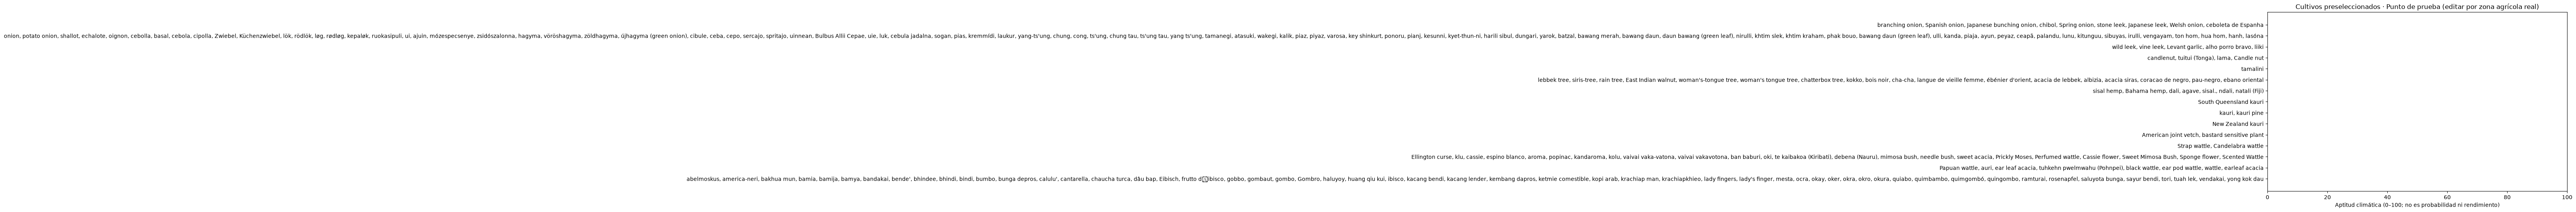

In [25]:
# Gráfico de los primeros 15 candidatos. La puntuación es relativa al modelo EcoCrop usado.
top = recommendations.head(15).sort_values("aptitud_climatica_0_100")
plt.figure(figsize=(10, 6))
plt.barh(top["cultivo"], top["aptitud_climatica_0_100"], color="#4b8b3b")
plt.xlabel("Aptitud climática (0–100; no es probabilidad ni rendimiento)")
plt.title(f"Cultivos preseleccionados · {ZONE_NAME}")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


## 6. Cómo interpretar y ampliar el resultado

- La lista es una **preselección climática regional** basada en los datos del punto/celda POWER y los límites EcoCrop. Verifica los nombres comunes: pueden estar en inglés o variar por región.
- Para valorar suelo y relieve, contrasta los candidatos con **FAO GAEZ v5**, que publica mapas de aptitud específicos por cultivo y considera clima, suelo y terreno. Evita combinar sus clases con el score del notebook sin normalizar definiciones y periodos.
- La aplicación NASA Field Shift ya contiene adaptadores para NASA POWER y observaciones Landsat. NDVI/NDMI pueden ayudar a monitorear vegetación y humedad superficial a lo largo del tiempo, pero no identifican por sí solos el cultivo adecuado ni sustituyen análisis de suelo.
- Un recomendador ML entrenado requiere datos históricos locales por zona y cultivo (siembra, manejo, agua, cosecha/rendimiento y años). Sin esas etiquetas, un ranking por reglas agronómicas es más transparente que entrenar con etiquetas inventadas.

Fuentes: [NASA POWER Daily API](https://power.larc.nasa.gov/docs/services/api/temporal/daily/); [FAO EcoCrop](https://www.fao.org/geospatial/data-and-tools/data-portals/ecocrop/); [OpenCLIM EcoCrop scoring/database](https://github.com/OpenCLIM/ecocrop); [FAO GAEZ v5](https://www.fao.org/gaez/en/).


In [26]:
# Guarda el ranking y las variables climáticas para reproducibilidad.
output_path = DATA_DIR / "recomendaciones_cultivos.csv"
recommendations.to_csv(output_path, index=False, encoding="utf-8-sig")
monthly_climatology.to_csv(DATA_DIR / "climatologia_mensual_power.csv", encoding="utf-8-sig")
metadata_path = DATA_DIR / "metadata_fuentes.json"
metadata_path.write_text(json.dumps({
    "zona": ZONE_NAME,
    "latitude": ZONE_LAT,
    "longitude": ZONE_LON,
    "periodo_start": START_DATE,
    "periodo_end": END_DATE,
    "fuente_clima": "NASA POWER Daily API",
    "fuente_perfiles": ECOCROP_URL,
    "metodo": "ventanas de ciclo EcoCrop aproximadas; puntaje=min(temperatura, precipitacion); media de mejor ventana por año",
    "nota": "Preseleccion climatica regional; no es rendimiento ni recomendacion agronomica validada.",
}, ensure_ascii=False, indent=2), encoding="utf-8")
print("Resultados guardados en:", output_path.resolve())


Resultados guardados en: D:\Documentos_Guille\GitHub\NASA_SPACE_APPS_HACKATON\ml\data\recomendaciones_cultivos.csv
